# Differential expression

Run from the repository root after `python -m scripts.download_data` and `python -m scripts.run_analysis`. These notebooks use reusable functions from `src/`. Observations come from GSE45827, not from the historical coursework.

## Research question

Which mapped genes differ between source-labelled groups after batch adjustment?

## Data and methods

Use a fixed-effects subtype-plus-batch model with empirical-Bayes variance moderation and BH FDR.

Genes tested: 13823 FDR<0.05: 4310
gene_symbol  log2_fold_change  effect_size  t_moderated      p_value  adjusted_p_value  significant_fdr05  mean_log2_intensity
      MIEN1          3.415481     3.415481    13.362285 5.749519e-19      7.947560e-15               True            10.771644
      PGAP3          3.946673     3.946673    11.954292 5.745166e-17      3.651755e-13               True             9.055216
      ERBB2          3.349501     3.349501    11.858734 7.925389e-17      3.651755e-13               True            11.975259
     STARD3          3.349953     3.349953    11.507350 2.612935e-16      9.029649e-13               True             8.329689
      SPAG5          3.380510     3.380510    10.990416 1.554469e-15      4.297485e-12               True             5.189855
       TPX2          3.562815     3.562815    10.745015 3.666378e-15      7.982733e-12               True             6.058706
       GRB7          3.987973     3.987973    10.717218 4.042475e-15      7.

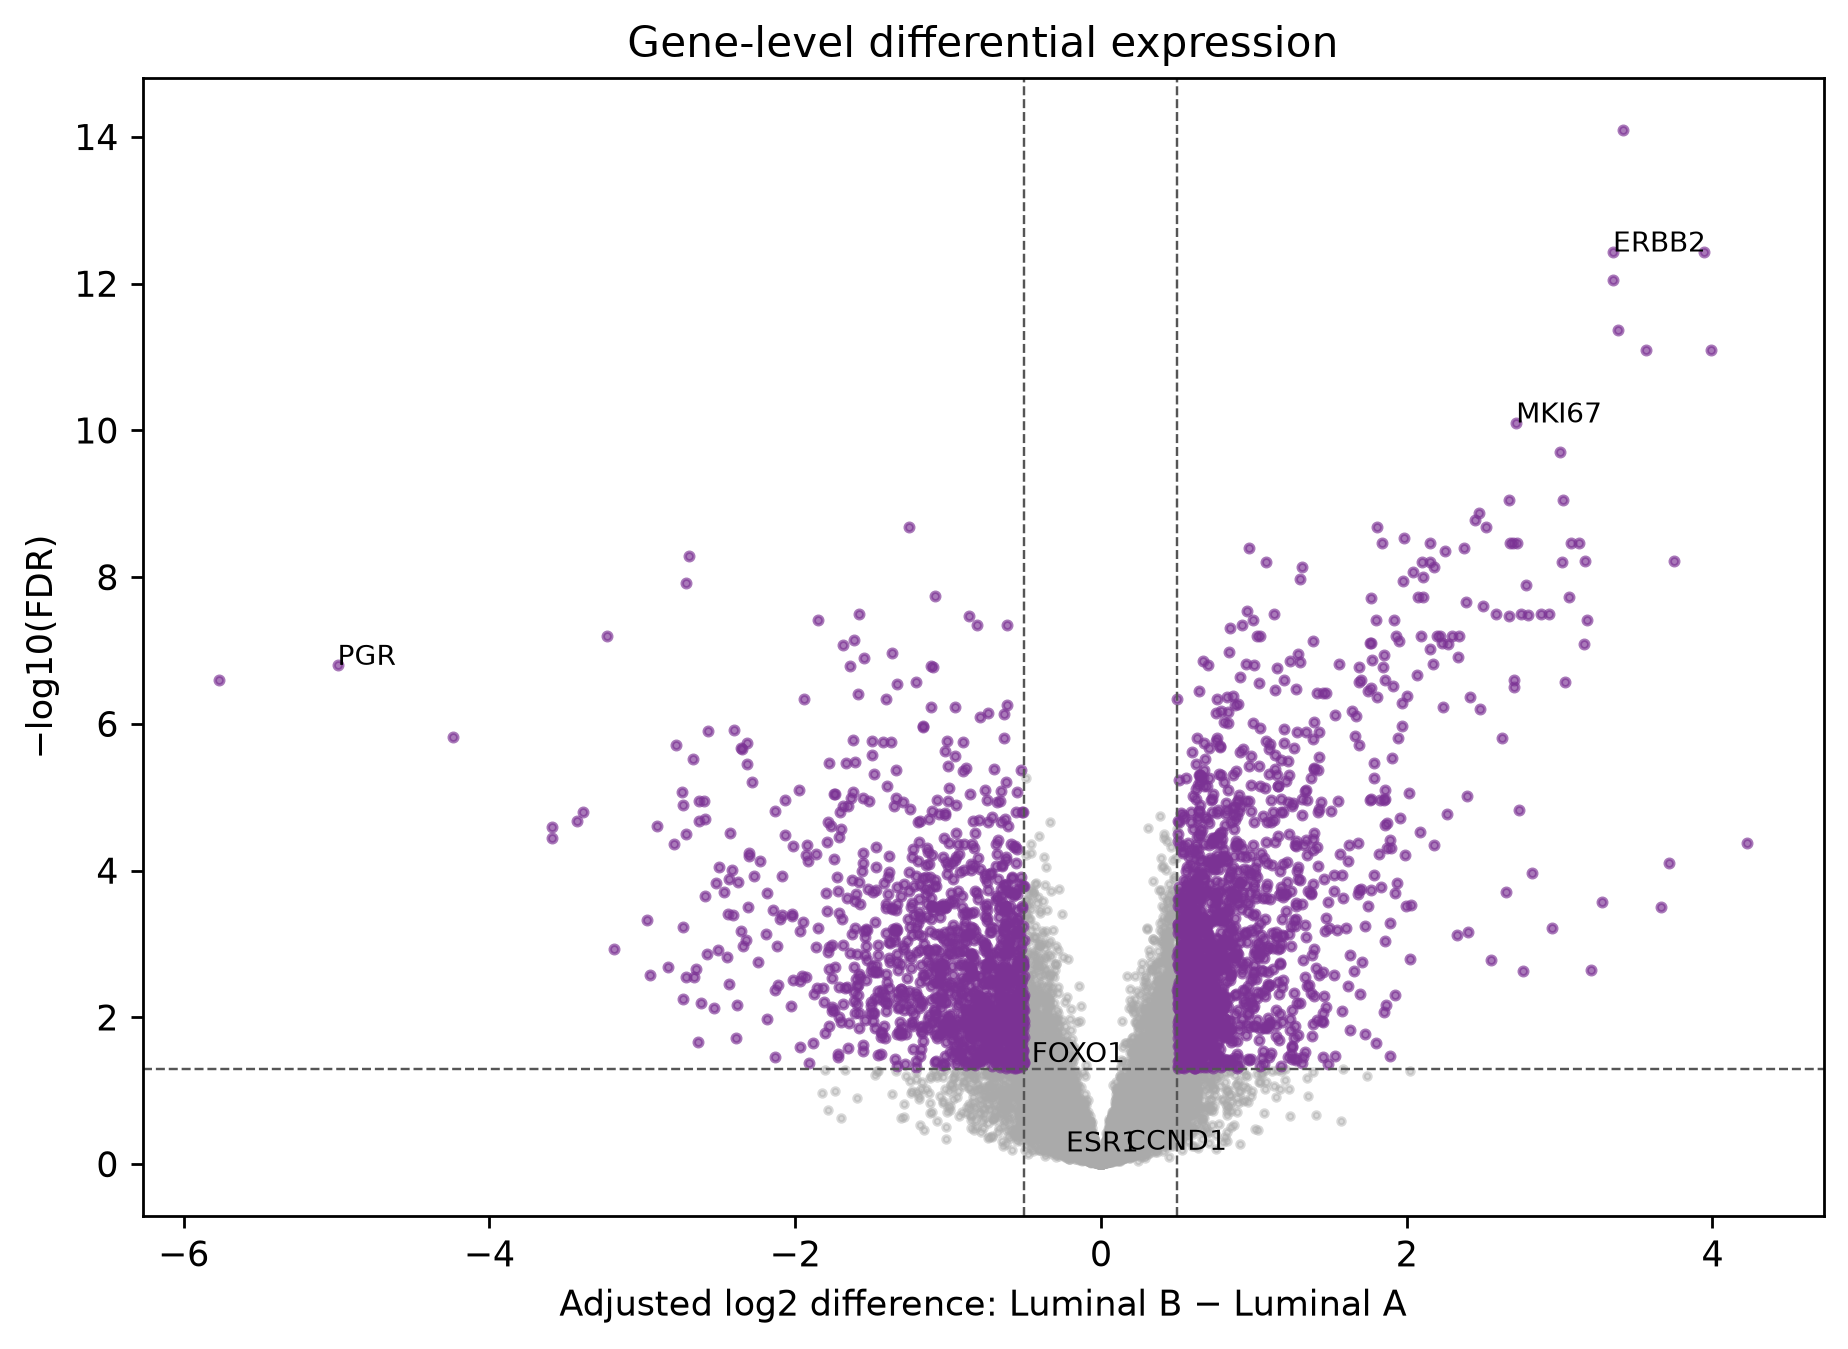

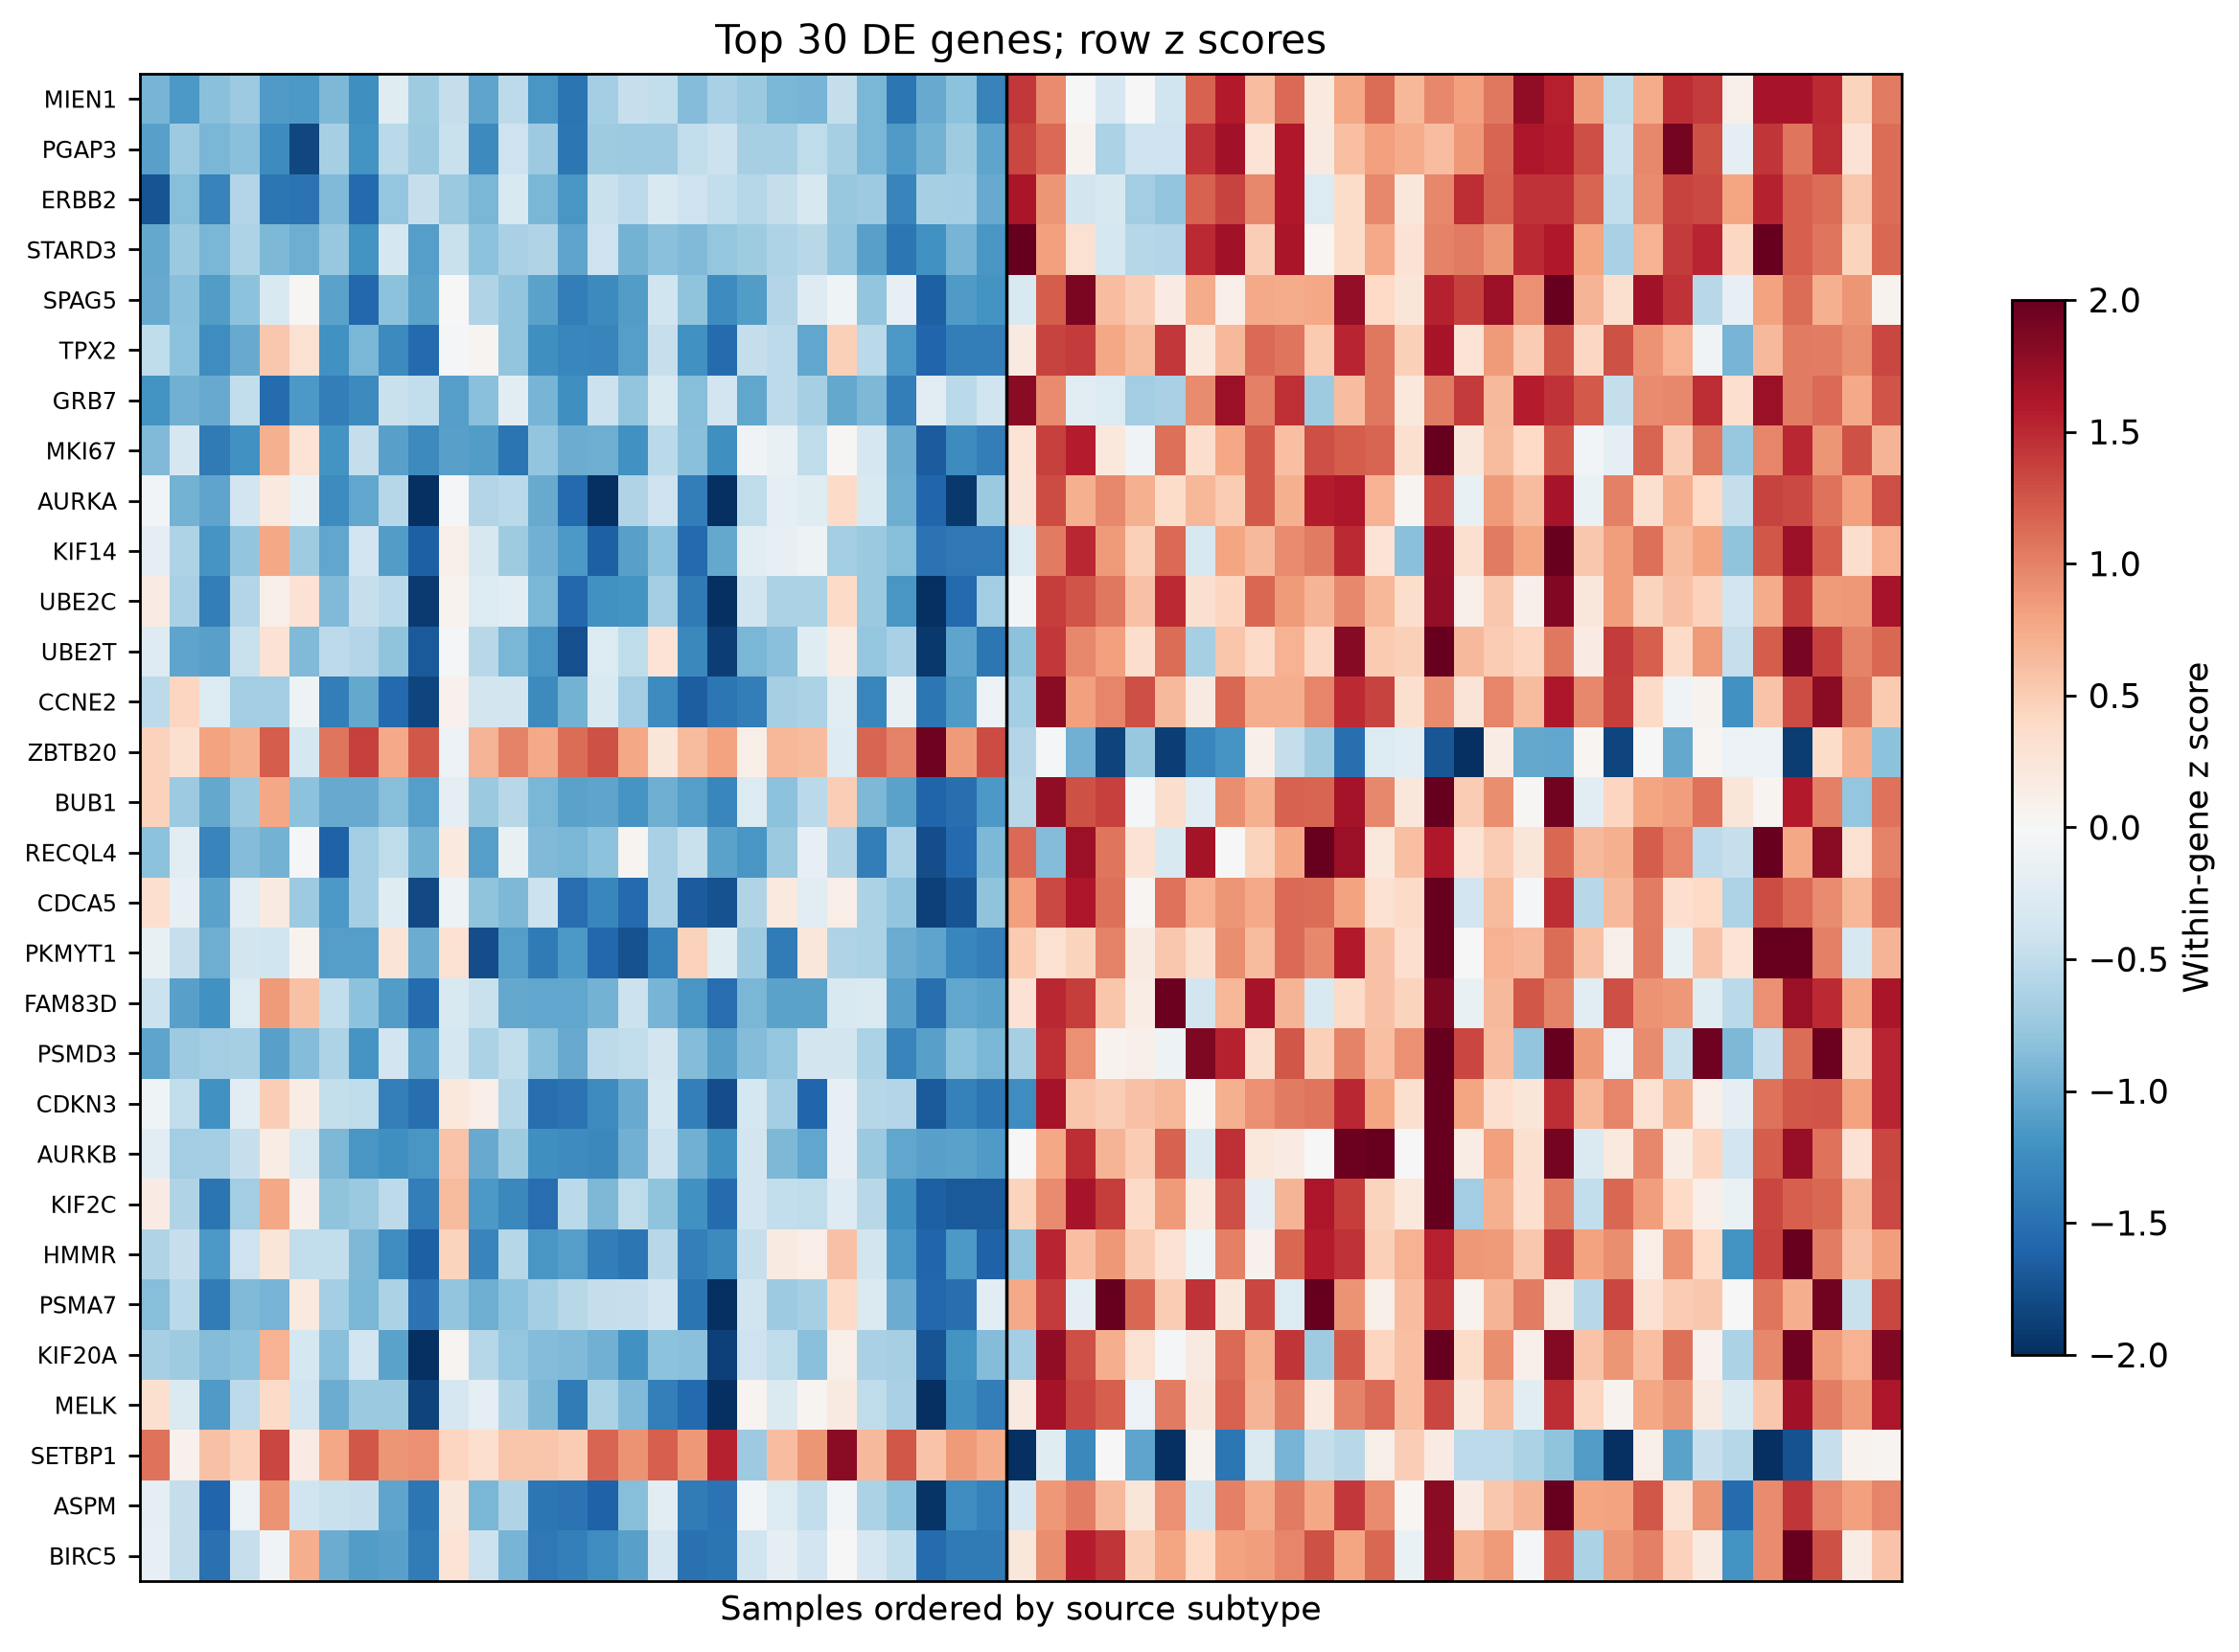

In [1]:
from pathlib import Path
from src.data_loading import parse_geo, load_annotation
from src.preprocessing import select_samples, gene_matrix
from src.differential_expression import fit_moderated
from src.visualization import volcano, heatmap
expression, all_metadata = parse_geo(Path('data/raw/GSE45827_series_matrix.txt.gz'))
selected, metadata = select_samples(expression, all_metadata)
genes, mapping = gene_matrix(selected, load_annotation(Path('data/raw/GPL570.annot.gz')))
de = fit_moderated(genes, metadata)
print('Genes tested:', len(de), 'FDR<0.05:', sum(de.significant_fdr05))
print(de.head(10).to_string(index=False))
volcano(de, Path('figures'))
heatmap(genes, metadata, de, Path('figures'))
from IPython.display import display, Image
display(Image(filename='figures/03_volcano.png'))
display(Image(filename='figures/04_heatmap.png'))

## Biological interpretation

Positive coefficients indicate higher log2 signal in labelled Luminal B. The heatmap is scaled within each gene.

## Limitations

This independent limma-style implementation is not formally cross-validated against Bioconductor limma; unmeasured covariates remain.